<a href="https://colab.research.google.com/github/Purvi955/credit-card-fraud-detection-ml/blob/main/Copy_of_Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=5000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    weights=[0.98, 0.02],
    random_state=42
)

df = pd.DataFrame(X, columns=[
    f"feature_{i}" for i in range(1, 11)
])

df["fraud"] = y

print(df.head())
print("\nDataset shape:", df.shape)
print("\nFraud distribution:")
print(df["fraud"].value_counts())


   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0   3.316690  -2.029674   2.355629  -0.215829  -1.419279   0.914109   
1   4.161930  -3.898558   0.174588  -0.091221  -1.360185  -0.606968   
2  -0.477509   3.103860   2.694822   1.562327   4.191341   1.230190   
3  -1.894990   2.218811  -0.062834  -2.495924  -1.738007  -1.256467   
4   1.060948  -0.626044  -0.793103   0.230642   2.636886  -0.128588   

   feature_7  feature_8  feature_9  feature_10  fraud  
0  -5.980685   1.518092  -0.042540   -3.397662      0  
1  -4.648657  -2.454777  -0.667688   -0.629240      0  
2   3.491643   0.827346   0.635312   -2.593035      0  
3  -1.842087   1.668228   0.494795   -0.994083      0  
4   1.756074  -0.774238  -1.772399    0.794834      0  

Dataset shape: (5000, 11)

Fraud distribution:
fraud
0    4874
1     126
Name: count, dtype: int64


In [ ]:

# Step 4: Split data into training and testing sets

X = df.drop("fraud", axis=1)
y = df["fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Step 5: Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Train the model
model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")


Training rows: 4000
Testing rows: 1000
Model training completed successfully!


In [ ]:

# Predict fraud on the test data
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Legitimate", "Fraud"]
))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))


Confusion Matrix:
[[695 280]
 [  5  20]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      0.71      0.83       975
       Fraud       0.07      0.80      0.12        25

    accuracy                           0.71      1000
   macro avg       0.53      0.76      0.48      1000
weighted avg       0.97      0.71      0.81      1000

ROC-AUC Score: 0.8045948717948718


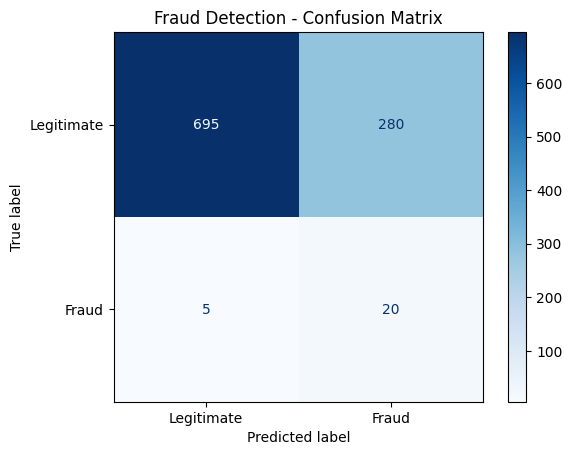

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues"
)

plt.title("Fraud Detection - Confusion Matrix")
plt.show()


In [ ]:

import pandas as pd

url = "https://huggingface.co/datasets/anshikapanwarr/creditcard-fraud/resolve/main/creditcard.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

print("\nFraud distribution:")
print(df["Class"].value_counts())


Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Fraud distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:

# Check and prepare the real dataset

print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nFraud percentage:")
print(round(df["Class"].mean() * 100, 3), "%")


Dataset shape: (284807, 31)

Missing values: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage:
0.173 %


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, roc_auc_score

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the model
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))


Confusion Matrix:
[[55478  1386]
 [    8    90]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

ROC-AUC: 0.9720834996210077


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": model,
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
}

results = []

for name, clf in models.items():
    if name != "Logistic Regression":
        clf.fit(X_train, y_train)
        predictions = clf.predict(X_test)
        probabilities = clf.predict_proba(X_test)[:, 1]
    else:
        predictions = clf.predict(X_test_scaled)
        probabilities = clf.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.0610,0.9184,0.1144,0.9721
1,Decision Tree,0.0693,0.8265,0.1279,0.9075
2,Random Forest,0.8316,0.8061,0.8187,0.9753


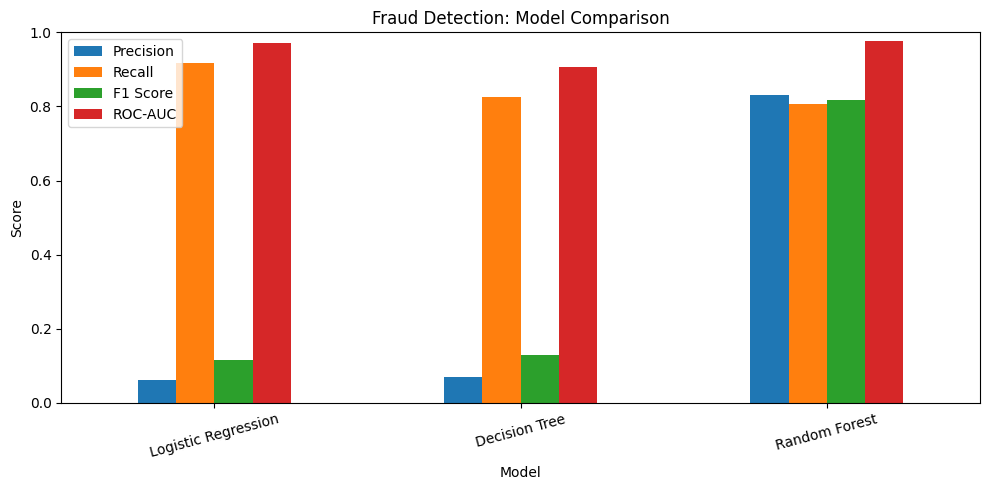

In [ ]:

results_df.set_index("Model")[["Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Fraud Detection: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
